# Lab 2A — 01. Eksploracja danych (BDD100K)

Podzbiór oficjalnych splitów (`1050` train / `150` val / `300` test, `seed=42`) oraz analiza adnotacji i przypadków szczególnych.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()

from pathlib import Path
from collections import Counter
from dataclasses import dataclass, asdict
import hashlib
import json
import time

import cv2
import numpy as np
import pandas as pd

CLASSES = ('traffic_sign', 'traffic_light')
COLORS = ('red', 'yellow', 'green', 'unknown')


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')


def load_image(path):
    # imdecode obsługuje polskie znaki w ścieżce także na Windows.
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Nie można odczytać obrazu: {path}')
    return image


def inventory(root, split='train'):
    """Odczytuje nazwy i rozmiary; niczego nie rozpakowuje ani nie modyfikuje."""
    root = Path(root)
    images = {}
    if split not in ('train', 'val', 'test'):
        raise ValueError(split)
    for folder in sorted((root / 'bdd100k_images_100k').glob(f'**/{split}')):
        for path in folder.glob('*.jpg'):
            images[path.stem] = path
    labels = sorted((root / 'bdd100k_labels').glob(f'**/{split}/*.json'))
    pairs = []
    for label in labels:
        image = images.get(label.stem)
        if image is not None and image.stat().st_size > 0 and label.stat().st_size > 0:
            pairs.append({'id': label.stem, 'image': image.relative_to(root).as_posix(),
                          'label': label.relative_to(root).as_posix()})
    return pairs, {'split': split, 'images': len(images), 'labels': len(labels),
                   'paired': len(pairs), 'unpaired_images': len(images.keys() - {p.stem for p in labels}),
                   'unpaired_labels': len(labels) - len(pairs)}


def annotations(path, shape=None):
    """Format dostarczonej wersji: frames[0].objects; wspiera też listę labels."""
    data = read_json(path)
    frames = data.get('frames', [])
    objects = frames[0].get('objects', []) if frames else data.get('labels', [])
    result, problems = [], Counter()
    for obj in objects:
        category = obj.get('category', '').replace(' ', '_')
        if category not in CLASSES:
            continue
        box = obj.get('box2d')
        if not box:
            problems['missing_box'] += 1
            continue
        try:
            coords = np.array([box[k] for k in ('x1', 'y1', 'x2', 'y2')], float)
        except (KeyError, ValueError, TypeError):
            problems['invalid_box'] += 1
            continue
        if not np.isfinite(coords).all() or coords[2] <= coords[0] or coords[3] <= coords[1]:
            problems['invalid_box'] += 1
            continue
        if shape is not None:
            h, w = shape[:2]
            clipped = np.clip(coords, [0, 0, 0, 0], [w, h, w, h])
            if not np.array_equal(clipped, coords):
                problems['clipped_box'] += 1
            coords = clipped
            if coords[2] <= coords[0] or coords[3] <= coords[1]:
                problems['empty_after_clip'] += 1
                continue
        attrs = obj.get('attributes', {})
        color = attrs.get('trafficLightColor', 'unknown')
        if color not in COLORS:
            color = 'unknown'
        result.append({'class': category, 'box': coords.tolist(),
                       'color': color if category == 'traffic_light' else None,
                       'occluded': bool(attrs.get('occluded', False)),
                       'truncated': bool(attrs.get('truncated', False))})
    return result, data.get('attributes', {}), dict(problems)


def make_manifest(root, output, n=1500, seed=42):
    """Podzbiór oficjalnych train/val/test, w proporcji 70/10/20. Bez mieszania."""
    output = Path(output)
    if output.exists():
        manifest = read_json(output)
        if manifest['seed'] != seed or manifest['n'] != n:
            raise ValueError('Istniejący podział ma inne n/seed. Użyj nowego katalogu eksperymentu.')
        return manifest
    if n < 1000:
        raise ValueError('Polecenie wymaga co najmniej 1000 obrazów.')
    sizes = {'train': int(.7*n), 'val': int(.1*n)}
    sizes['test'] = n-sum(sizes.values())
    splits, counts = {}, {}
    rng = np.random.default_rng(seed)
    for split, size in sizes.items():
        pairs, counts[split] = inventory(root, split)
        if len(pairs) < size:
            raise RuntimeError(f'{split}: za mało par: {len(pairs)} / {size}.')
        order = rng.permutation(len(pairs))[:size]
        splits[split] = [pairs[i] for i in order]
        for item in splits[split]:
            image = load_image(Path(root) / item['image'])
            annotations(Path(root) / item['label'], image.shape)
    all_ids = [r['id'] for records in splits.values() for r in records]
    if len(all_ids) != len(set(all_ids)):
        raise ValueError('Powtórzone identyfikatory między oficjalnymi splitami.')
    manifest = {'seed': seed, 'n': n, 'source': 'official_train_val_test',
                'inventory': counts, 'splits': splits}
    save_json(output, manifest)
    return manifest


def iou(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    wh = np.maximum(0, np.minimum(a[2:], b[2:]) - np.maximum(a[:2], b[:2]))
    inter = float(np.prod(wh))
    union = float(np.prod(a[2:]-a[:2]) + np.prod(b[2:]-b[:2]) - inter)
    return inter / union if union > 0 else 0.


def nms(items, threshold=.35):
    kept = []
    for item in sorted(items, key=lambda x: x['score'], reverse=True):
        if all(item['class'] != old['class'] or iou(item['box'], old['box']) <= threshold for old in kept):
            kept.append(item)
    return kept


@dataclass(frozen=True)
class Params:
    saturation: int = 85
    value: int = 65
    sign_min_area: int = 45
    light_min_area: int = 25
    score_threshold: float = .38
    max_y: float = .85


def masks(image, p):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    valid = (s >= p.saturation) & (v >= p.value)
    # OpenCV: H ma zakres 0..179. Czerwony przechodzi przez koniec skali.
    return hsv, {'red': valid & ((h <= 12) | (h >= 165)),
                 'yellow': valid & (h >= 15) & (h <= 38),
                 'green': valid & (h >= 40) & (h <= 95),
                 'blue': valid & (h >= 96) & (h <= 130)}


def contours(mask, close=3):
    mask = np.uint8(mask) * 255
    if close:
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((close, close), np.uint8))
    return cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]


def classify_color(crop, p):
    if crop.size == 0:
        return 'unknown'
    _, mm = masks(crop, p)
    scores = {}
    for color in COLORS[:3]:
        areas = [cv2.contourArea(c) for c in contours(mm[color], close=0)]
        scores[color] = max(areas, default=0.)
    ranking = sorted(scores, key=scores.get, reverse=True)
    best, second = ranking[:2]
    if scores[best] < max(2., crop.shape[0]*crop.shape[1]*.006) or scores[best] < 1.4*scores[second]:
        return 'unknown'
    return best


def detect(image, p=Params()):
    """HSV + kontury + geometria. Wszystkie ramki w oryginalnej skali obrazu."""
    h, w = image.shape[:2]
    hsv, mm = masks(image, p)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    candidates = []
    # Znaki kolorowe oraz jasne tablice (np. ograniczenie prędkości w USA).
    white = (hsv[:, :, 1] < 65) & (hsv[:, :, 2] > 165)
    sign_masks = [mm['red'] | mm['yellow'] | mm['blue'] | mm['green'], white]
    for mask in sign_masks:
        for c in contours(mask):
            x, y, bw, bh = cv2.boundingRect(c)
            area = bw*bh
            if not (p.sign_min_area <= area <= .06*w*h and .35 <= bw/bh <= 3.5 and y < p.max_y*h):
                continue
            fill = cv2.contourArea(c)/area
            hull_area = cv2.contourArea(cv2.convexHull(c))
            solidity = cv2.contourArea(c) / hull_area if hull_area else 0.
            if fill < .4 or solidity < .75:
                continue
            edge = cv2.Canny(gray[y:y+bh, x:x+bw], 70, 150).mean()/255
            if edge < .025:
                continue
            score = float(min(1., .45*fill + .35*min(edge*8, 1) + .2))
            candidates.append({'class': 'traffic_sign', 'box': [x,y,x+bw,y+bh], 'score': score, 'color': None})
    # Obudowy sygnalizatorów: ciemne, zwarte pionowe lub poziome prostokąty.
    dark = gray < 65
    light_boxes = []
    for c in contours(dark):
        x, y, bw, bh = cv2.boundingRect(c)
        if not (p.light_min_area <= bw*bh <= .025*w*h and y < p.max_y*h):
            continue
        ratio = bw/bh
        if not (.18 <= ratio <= .8 or 1.5 <= ratio <= 5.):
            continue
        fill = cv2.contourArea(c)/(bw*bh)
        if fill >= .4:
            light_boxes.append(([x,y,x+bw,y+bh], fill, False))
    # Mała świecąca lampa może nie połączyć się z obudową w masce ciemności.
    # Rozszerzenie to hipoteza geometrii, nie ramka referencyjna.
    # Świecące punkty muszą być jaśniejsze i bardziej nasycone niż zwykły znak.
    lamp_valid = (hsv[:,:,1] >= max(p.saturation,110)) & (hsv[:,:,2] >= 155)
    for color in COLORS[:3]:
        for c in contours(mm[color] & lamp_valid, close=0):
            x,y,bw,bh = cv2.boundingRect(c)
            fill = cv2.contourArea(c)/(bw*bh)
            if 5 <= bw*bh <= 500 and .55 <= bw/bh <= 1.8 and fill >= .45 and y < p.max_y*h:
                for shift in (0., 1., 2.):
                    light_boxes.append(([x-.4*bw,y-shift*bh,x+1.4*bw,y+(3-shift)*bh], .5, True))
    for box, fill, expanded in light_boxes:
        x1,y1,x2,y2 = np.clip(box, [0,0,0,0], [w,h,w,h]).astype(int)
        crop = image[y1:y2,x1:x2]
        if expanded and (crop.size == 0 or np.mean(cv2.cvtColor(crop,cv2.COLOR_BGR2GRAY) < 85) < .35):
            continue
        color = classify_color(crop, p)
        score = float(.25 + .25*fill + (.3 if color != 'unknown' else 0) - (.05 if expanded else 0))
        candidates.append({'class': 'traffic_light', 'box': [int(x1),int(y1),int(x2),int(y2)],
                           'score': score, 'color': color})
    return nms([item for item in candidates if item['score'] >= p.score_threshold])


def match(pred, gt, category, threshold=.5):
    """Greedy po score; jeden GT najwyżej raz. Kolor nie wpływa na dopasowanie."""
    pi = sorted([i for i,p in enumerate(pred) if p['class']==category], key=lambda i: -pred[i]['score'])
    remaining = {i for i,g in enumerate(gt) if g['class']==category}
    matches, fp = [], []
    for i in pi:
        j = max(remaining, key=lambda j: (iou(pred[i]['box'], gt[j]['box']), -j), default=None)
        if j is not None and iou(pred[i]['box'], gt[j]['box']) >= threshold:
            matches.append((i,j))
            remaining.remove(j)
        else:
            fp.append(i)
    return matches, fp, sorted(remaining)


def evaluate(root, records, p, predictions=None):
    rows, errors, color_pairs, saved = [], [], [], {}
    counts = {c: Counter(TP=0, FP=0, FN=0) for c in CLASSES}
    started = time.perf_counter()
    for record in records:
        image = load_image(Path(root)/record['image'])
        gt, _, _ = annotations(Path(root)/record['label'], image.shape)
        pred = predictions[record['id']] if predictions is not None else detect(image, p)
        saved[record['id']] = pred
        for category in CLASSES:
            matched, fp, fn = match(pred, gt, category)
            counts[category].update(TP=len(matched), FP=len(fp), FN=len(fn))
            for pi, gi in matched:
                if category == 'traffic_light':
                    color_pairs.append((gt[gi]['color'], pred[pi]['color']))
            for index in fp:
                errors.append({'id':record['id'], 'type':'FP', 'class':category, 'box':pred[index]['box']})
            for index in fn:
                errors.append({'id':record['id'], 'type':'FN', 'class':category, 'box':gt[index]['box']})
    for category, c in counts.items():
        tp, fp, fn = c['TP'], c['FP'], c['FN']
        rows.append({'class':category, **c, 'precision':tp/(tp+fp) if tp+fp else 0.,
                     'recall':tp/(tp+fn) if tp+fn else 0.,
                     'F1':2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.})
    matrix = pd.DataFrame(0, index=COLORS, columns=COLORS)
    for actual, predicted in color_pairs:
        matrix.loc[actual, predicted] += 1
    return {'metrics':pd.DataFrame(rows), 'confusion':matrix, 'errors':errors, 'predictions':saved,
            'seconds':time.perf_counter()-started, 'matched_lights':len(color_pairs),
            'color_accuracy':sum(a==b for a,b in color_pairs)/len(color_pairs) if color_pairs else None}


def draw(image, boxes, title='', ax=None):
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    if ax is None:
        _, ax = plt.subplots(figsize=(14,8))
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    for item in boxes:
        x1,y1,x2,y2 = item['box']
        color = 'lime' if item['class']=='traffic_sign' else 'cyan'
        ax.add_patch(Rectangle((x1,y1), x2-x1,y2-y1,fill=False,edgecolor=color,linewidth=1.3))
        label = item['class'] + (f"/{item['color']}" if item.get('color') else '')
        ax.text(x1,y1,label,color='black',fontsize=6,bbox={'facecolor':color,'alpha':.7,'pad':1})
    ax.set(title=title)
    ax.axis('off')
    return ax


def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()
N, SEED = 1500, 42
EXP = ROOT/'outputs'/f'official_{N}_seed{SEED}'
manifest = make_manifest(ROOT,EXP/'manifest.json',N,SEED)
assert manifest['source']=='official_train_val_test', 'Użyj manifestu oficjalnych splitów.'
splits = manifest['splits']
print('Podział:',{k:len(v) for k,v in splits.items()})
print('Wyniki:',EXP)

Podział: {'train': 1050, 'val': 150, 'test': 300}
Wyniki: c:\Users\hubi_\Desktop\Dane\Studia\AGH\III sem\Rozpoznawanie wzorców\lab4\outputs\official_1500_seed42


In [2]:
inventory_rows = []
for split in ('train','val','test'):
    _,counts = inventory(ROOT,split)
    inventory_rows.append(counts)
display(pd.DataFrame(inventory_rows))
print('Brak JSON jest czymś innym niż JSON z pustą listą obiektów.')
print('Pary niekompletne nie wchodzą do eksperymentu; tabela wyżej pokazuje ich liczbę.')

,split,images,labels,paired,unpaired_images,unpaired_labels
0,train,70000,70000,70000,0,0
1,val,10000,10000,10000,0,0
2,test,20000,20000,20000,0,0


Brak JSON jest czymś innym niż JSON z pustą listą obiektów.
Pary niekompletne nie wchodzą do eksperymentu; tabela wyżej pokazuje ich liczbę.


## Struktura adnotacji

Obiekty znajdują się w `frames[0]['objects']` (lub `labels`). Interesują nas klasy `traffic_sign` i `traffic_light` (z atrybutem `trafficLightColor`) zapisane jako `box2d`.

In [3]:
from pathlib import Path
from collections import Counter
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image


def raw_objects(data):
    frames = data.get('frames',[])
    return frames[0].get('objects',[]) if frames else data.get('labels',[])


def summarize_train(root,records):
    scenes,objects,categories,issues = [],[],Counter(),Counter()
    for record in records:
        data = read_json(Path(root)/record['label'])
        raw = raw_objects(data)
        # Nagłówek JPEG wystarcza do odczytu wymiarów; bez dekodowania całego zdjęcia.
        with Image.open(Path(root)/record['image']) as image:
            w,h = image.size
        truth,attrs,problems = annotations(Path(root)/record['label'],(h,w))
        issues.update(problems)
        categories.update(o.get('category','<missing>') for o in raw)
        row = {'id':record['id'],**attrs,'width':w,'height':h,
               'all_annotations':len(raw), 'all_bbox':sum('box2d' in o for o in raw),
               'poly2d':sum('poly2d' in o for o in raw),'targets':len(truth),
               'signs':sum(o['class']=='traffic_sign' for o in truth),
               'lights':sum(o['class']=='traffic_light' for o in truth),
               'occluded':any(o['occluded'] for o in truth),
               'truncated':any(o['truncated'] for o in truth),
               'tiny':any(min(o['box'][2]-o['box'][0],o['box'][3]-o['box'][1])<10 for o in truth)}
        for color in ('red','yellow','green','unknown'):
            row[color] = sum(o['color']==color for o in truth)
        scenes.append(row)
        for o in truth:
            x1,y1,x2,y2 = o['box']
            objects.append({'id':record['id'],'class':o['class'],'color':o['color'],
                            'width':x2-x1,'height':y2-y1,'occluded':o['occluded'],
                            'truncated':o['truncated']})
    return pd.DataFrame(scenes),pd.DataFrame(objects),categories,dict(issues)


def select_examples(scene):
    """Jawnie raportujemy brak danego przypadku zamiast podmieniać go innym."""
    conditions = {
        'Znaki, bez sygnalizatorów':(scene.signs>0)&(scene.lights==0),
        'Sygnalizatory, bez znaków':(scene.lights>0)&(scene.signs==0),
        'Znaki i sygnalizatory':(scene.signs>0)&(scene.lights>0),
        'Brak klas docelowych, inne adnotacje':(scene.targets==0)&(scene.all_annotations>0),
        'Całkowicie pusta lista obiektów':scene.all_annotations==0,
        'Czerwone światło':scene.red>0,'Żółte światło':scene.yellow>0,
        'Zielone światło':scene.green>0,'Kolor unknown':scene.unknown>0,
        'Obiekt zasłonięty':scene.occluded,'Obiekt ucięty':scene.truncated,
        'Mały obiekt (<10 px)':scene.tiny,
        'Wiele znaków (>=5)':scene.signs>=5,'Adnotacje polilinii':scene.poly2d>0}
    for column,value,title in [('timeofday','night','Noc'),('timeofday','dawn/dusk','Świt / zmierzch'),
                                ('weather','rainy','Deszcz'),('weather','snowy','Śnieg'),
                                ('weather','foggy','Mgła')]:
        if column in scene:
            conditions[title] = scene[column]==value
    rows = []
    used = set()
    for title,mask in conditions.items():
        available = scene.loc[mask,'id'].tolist()
        name = next((n for n in available if n not in used),available[0] if available else None)
        if name: used.add(name)
        rows.append({'example':title,'count_in_train':len(available),'id':name})
    return pd.DataFrame(rows)


def draw_all(image,data,ax):
    """Pozostałe bbox oraz polilinie, żeby rozróżnić brak celu od braku adnotacji."""
    ax.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
    raw = raw_objects(data)
    names = sorted(set(o.get('category','?') for o in raw))
    palette = plt.get_cmap('tab20')
    colors = {name:palette(i%20) for i,name in enumerate(names)}
    for obj in raw:
        name = obj.get('category','?'); color = colors[name]
        if 'box2d' in obj:
            b = obj['box2d']; x,y = b['x1'],b['y1']
            ax.add_patch(Rectangle((x,y),b['x2']-x,b['y2']-y,fill=False,color=color,linewidth=1))
            ax.text(x,y,name,fontsize=5,color='black',bbox={'facecolor':color,'alpha':.7,'pad':.5})
        poly = obj.get('poly2d',[])
        if poly:
            # Dostarczona wersja przechowuje punkty [x,y,typ]. To podgląd polilinii,
            # nie renderowanie krzywych Beziera ani maski segmentacyjnej.
            if isinstance(poly[0],list):
                xy = np.asarray([[p[0],p[1]] for p in poly],float)
                ax.plot(xy[:,0],xy[:,1],color=color,linewidth=1,linestyle='--',label=name)
    ax.axis('off')


def gallery(root,records,examples,out):
    lookup = {r['id']:r for r in records}
    selected = examples.loc[examples.id.notna()].to_dict('records')
    out = Path(out); out.mkdir(parents=True,exist_ok=True)
    for start in range(0,len(selected),6):
        fig,axes = plt.subplots(3,2,figsize=(17,15))
        for ax,item in zip(axes.ravel(),selected[start:start+6]):
            r = lookup[item['id']]
            image = load_image(Path(root)/r['image'])
            truth,attrs,_ = annotations(Path(root)/r['label'],image.shape)
            draw(image,truth,ax=ax)
            ax.set_title(item['example']+'\n'+r['id']+' | '+str(attrs),fontsize=8)
        for ax in axes.ravel()[len(selected[start:start+6]):]: ax.axis('off')
        fig.tight_layout(); fig.savefig(out/f'gallery_{start//6+1}.png',dpi=110)
        plt.show()


def crop_gallery(root,records,out):
    selected = {}
    for r in records:
        truth,_,_ = annotations(Path(root)/r['label'])
        for obj in truth:
            key = obj['class'] if obj['class']=='traffic_sign' else 'traffic_light_'+obj['color']
            b = obj['box']; area = (b[2]-b[0])*(b[3]-b[1])
            selected.setdefault(key,[]).append((area,r,obj))
    fig,axes = plt.subplots(2,5,figsize=(16,8))
    keys = ['traffic_sign','traffic_light_red','traffic_light_yellow','traffic_light_green','traffic_light_unknown']
    for row,mode in enumerate(['największy','najmniejszy']):
        for ax,key in zip(axes[row],keys):
            if key in selected:
                candidates = sorted(selected[key],key=lambda item:item[0])
                _,r,obj = candidates[-1] if row==0 else candidates[0]
                image = load_image(Path(root)/r['image'])
                x1,y1,x2,y2 = np.clip(obj['box'],[0,0,0,0],[image.shape[1],image.shape[0]]*2).astype(int)
                x2=max(x1+1,x2); y2=max(y1+1,y2)
                ax.imshow(cv2.cvtColor(image[y1:y2,x1:x2],cv2.COLOR_BGR2RGB))
                ax.set_title(key.replace('traffic_','')+f'\n{mode}: {x2-x1} × {y2-y1} px',fontsize=8)
            else: ax.set_title(key+'\nBRAK w train',fontsize=8)
            ax.axis('off')
    fig.tight_layout(); fig.savefig(Path(out)/'target_crops.png',dpi=130); plt.show()
train = splits['train']
example = train[0]
raw = read_json(ROOT/example['label'])
print(json.dumps({'name':raw.get('name'), 'attributes':raw.get('attributes'),
                  'first_objects':raw_objects(raw)[:3]},ensure_ascii=False,indent=2))
scene,obj,categories,issues = summarize_train(ROOT,train)
EDA = EXP/'eda'; EDA.mkdir(parents=True,exist_ok=True)
scene.to_csv(EDA/'train_images.csv',index=False)
obj.to_csv(EDA/'train_targets.csv',index=False)
display(pd.Series(categories,name='liczba adnotacji').sort_values(ascending=False).to_frame())
print('Problemy adnotacji:',issues)
display(scene[['all_annotations','all_bbox','poly2d','targets','signs','lights']].describe())

{
  "name": "ad930b5f-4298e268",
  "attributes": {
    "weather": "rainy",
    "scene": "residential",
    "timeofday": "daytime"
  },
  "first_objects": [
    {
      "category": "traffic sign",
      "id": 0,
      "attributes": {
        "occluded": false,
        "truncated": false,
        "trafficLightColor": "none"
      },
      "box2d": {
        "x1": 651.32761,
        "y1": 356.857656,
        "x2": 666.300659,
        "y2": 369.335197
      }
    },
    {
      "category": "traffic light",
      "id": 1,
      "attributes": {
        "occluded": false,
        "truncated": false,
        "trafficLightColor": "red"
      },
      "box2d": {
        "x1": 699.990018,
        "y1": 331.902575,
        "x2": 707.476542,
        "y2": 345.62787
      }
    },
    {
      "category": "traffic light",
      "id": 2,
      "attributes": {
        "occluded": false,
        "truncated": false,
        "trafficLightColor": "red"
      },
      "box2d": {
        "x1": 864.693552,
  

,liczba adnotacji
car,10656
traffic sign,3590
lane/single white,3554
traffic light,2866
lane/road curb,1647
lane/crosswalk,1518
person,1469
area/drivable,959
area/alternative,875
lane/double yellow,582


Problemy adnotacji: {'invalid_box': 4}


,all_annotations,all_bbox,poly2d,targets,signs,lights
count,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000,1050.000000
mean,27.643810,18.542857,9.100952,6.144762,3.417143,2.727619
std,12.995445,9.876577,5.708798,5.665610,3.449111,3.467141
min,4.000000,4.000000,0.000000,0.000000,0.000000,0.000000
25%,18.000000,11.000000,5.000000,2.000000,1.000000,0.000000
50%,26.000000,17.000000,9.000000,5.000000,3.000000,1.000000
75%,35.000000,24.000000,12.000000,9.000000,5.000000,5.000000
max,88.000000,62.000000,42.000000,33.000000,24.000000,19.000000


## Przypadki brzegowe i galeria

Rozróżniamy trzy sytuacje: obrazy bez klas docelowych (z innymi obiektami), puste listy obiektów oraz brakujące pliki.

,przypadek,obrazy
0,"bez klas docelowych, ale z innymi adnotacjami",132
1,zupełnie pusta lista obiektów,0
2,z klasami docelowymi,918


,example,count_in_train,id
0,"Znaki, bez sygnalizatorów",324,a75f21aa-b7d4097d
1,"Sygnalizatory, bez znaków",73,6cf618da-5a1882ed
2,Znaki i sygnalizatory,521,ad930b5f-4298e268
3,"Brak klas docelowych, inne adnotacje",132,6392bffb-ef25e984
4,Całkowicie pusta lista obiektów,0,NaN
5,Czerwone światło,275,0fc290b5-f43ff329
6,Żółte światło,30,a480fc56-d579eb33
7,Zielone światło,437,4fd75dca-47a89dad
8,Kolor unknown,332,4c7914dd-1a04c66b
9,Obiekt zasłonięty,276,4f21b6b4-44b83505


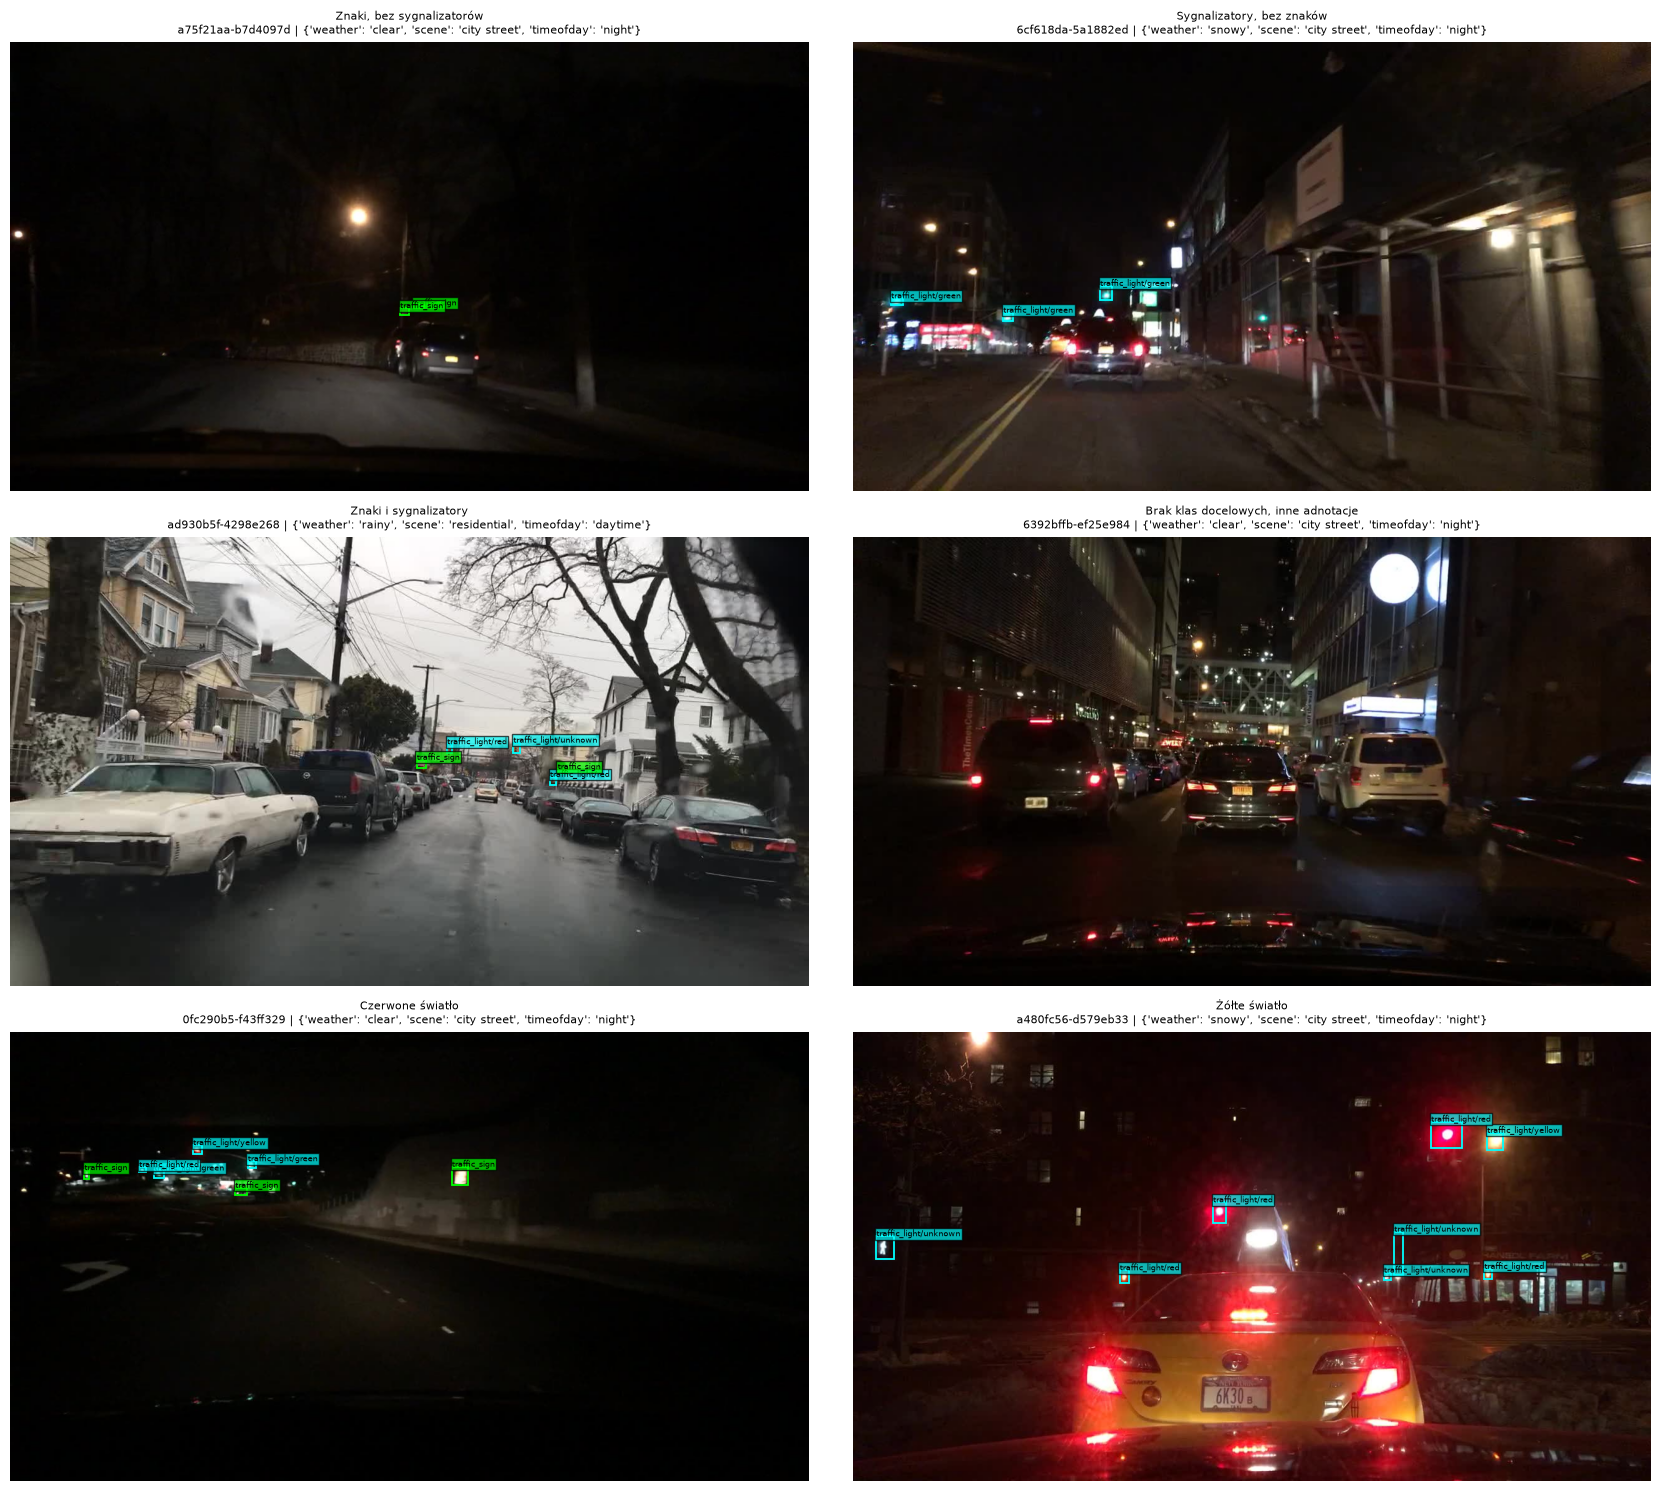

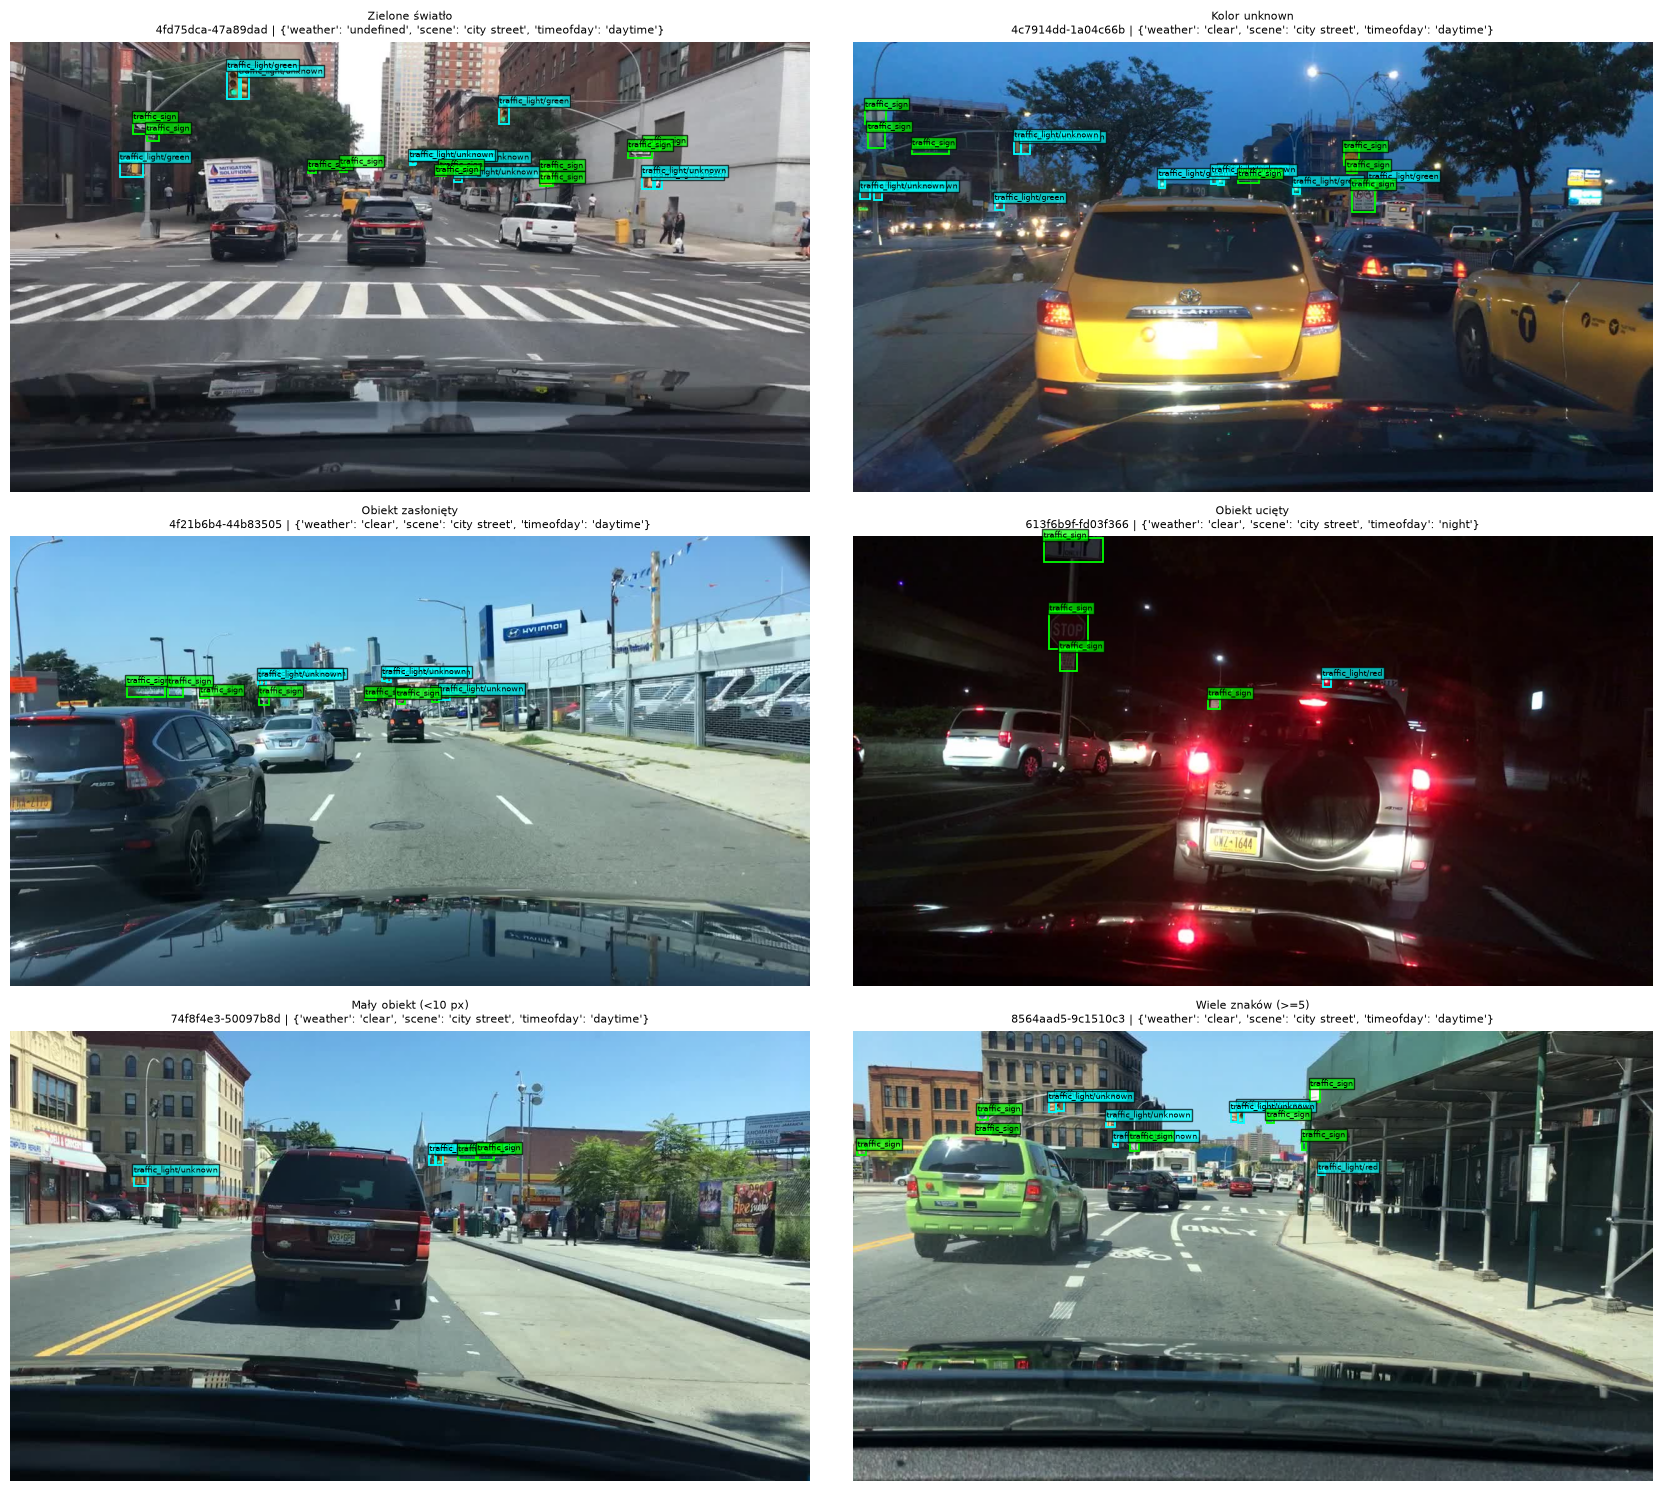

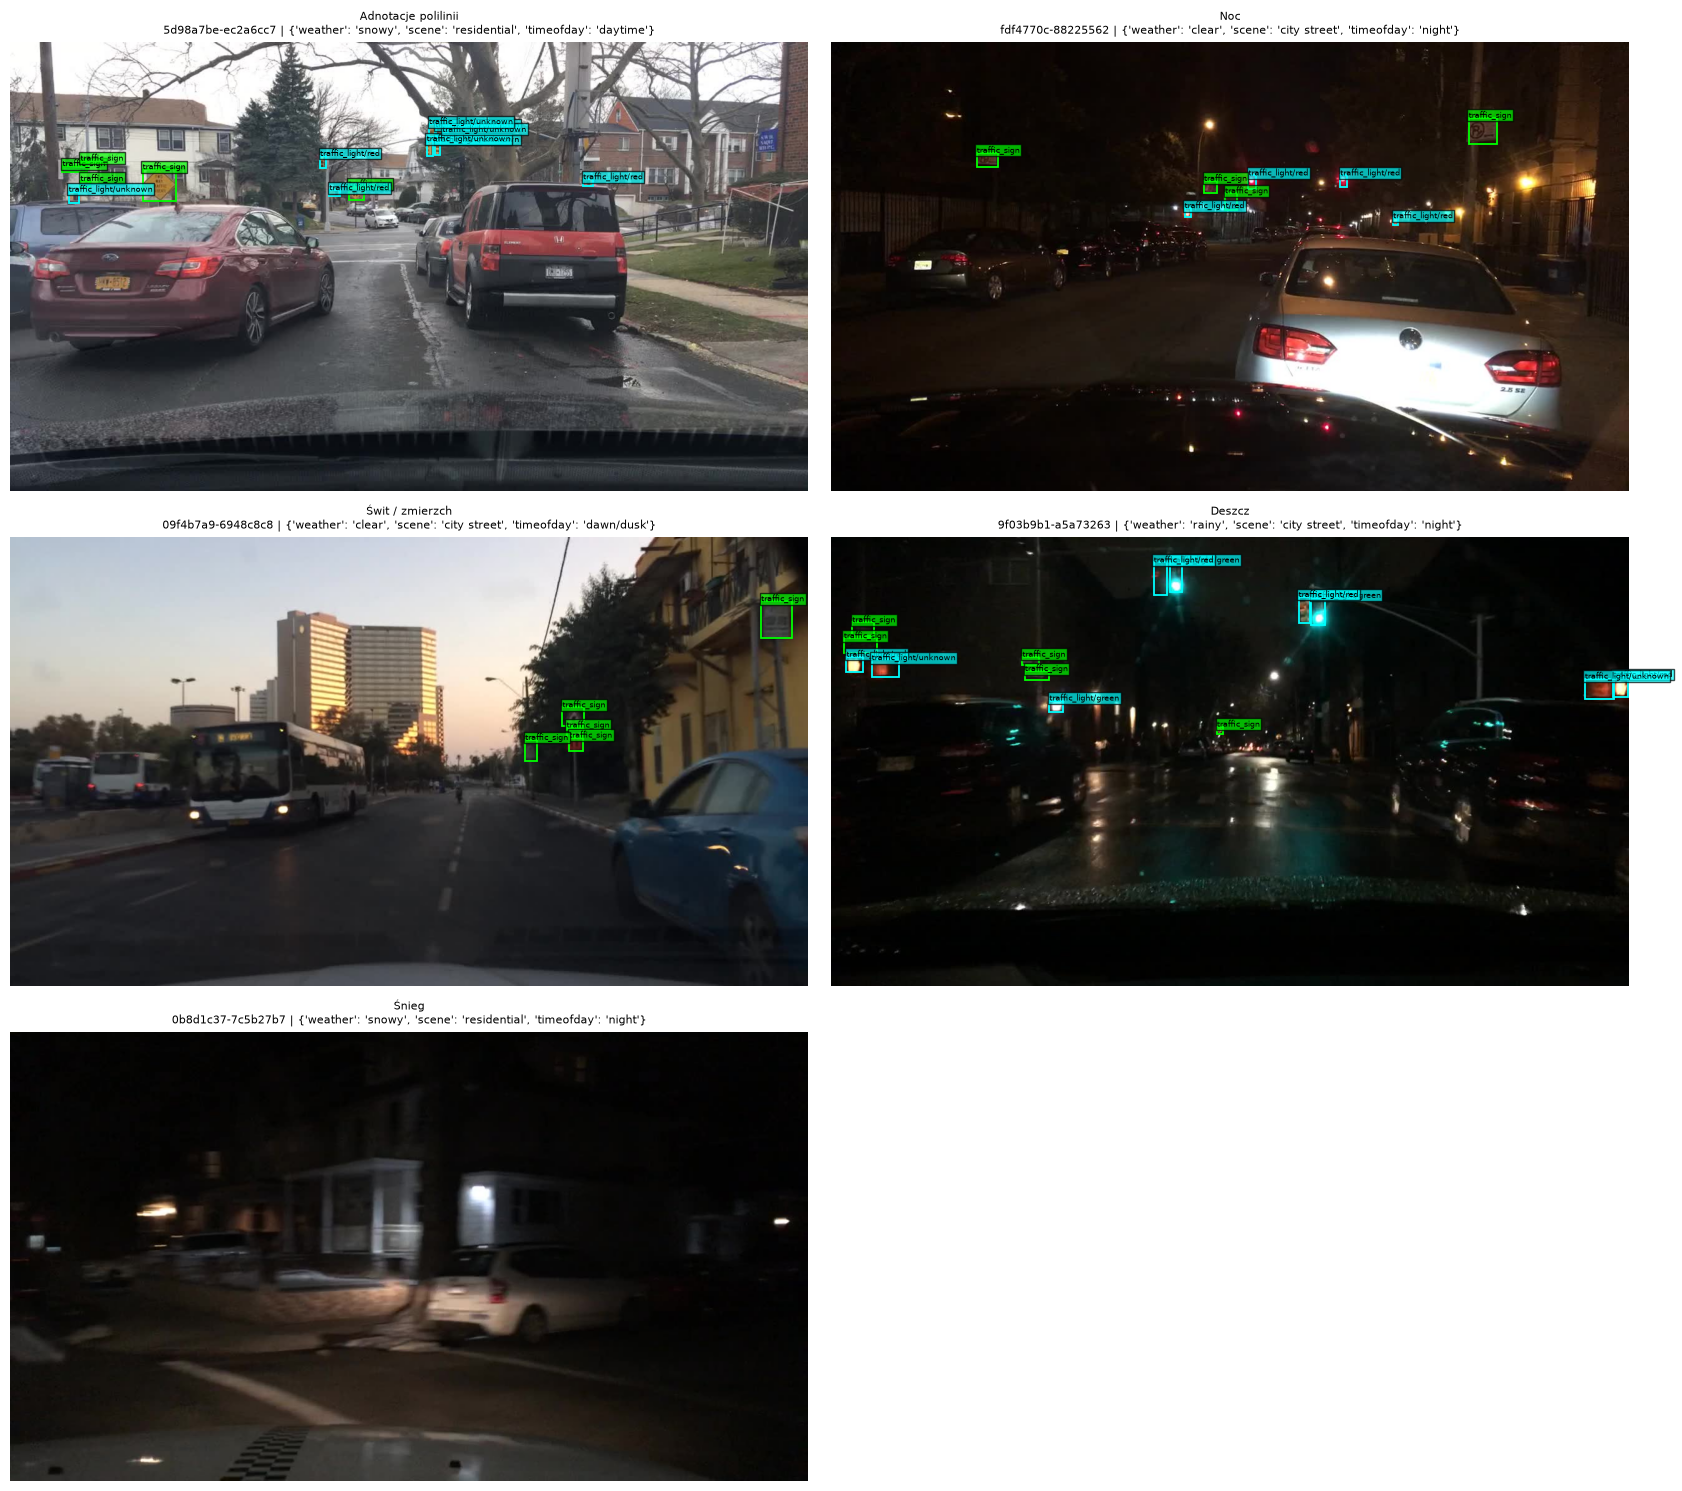

In [4]:
display(pd.DataFrame([
    {'przypadek':'bez klas docelowych, ale z innymi adnotacjami',
     'obrazy':int(((scene.targets==0)&(scene.all_annotations>0)).sum())},
    {'przypadek':'zupełnie pusta lista obiektów','obrazy':int((scene.all_annotations==0).sum())},
    {'przypadek':'z klasami docelowymi','obrazy':int((scene.targets>0).sum())}
]))
examples = select_examples(scene)
display(examples)
examples.to_csv(EDA/'gallery_catalog.csv',index=False)
gallery(ROOT,train,examples,EDA)

## Porównanie adnotacji (`box2d` vs `poly2d`)

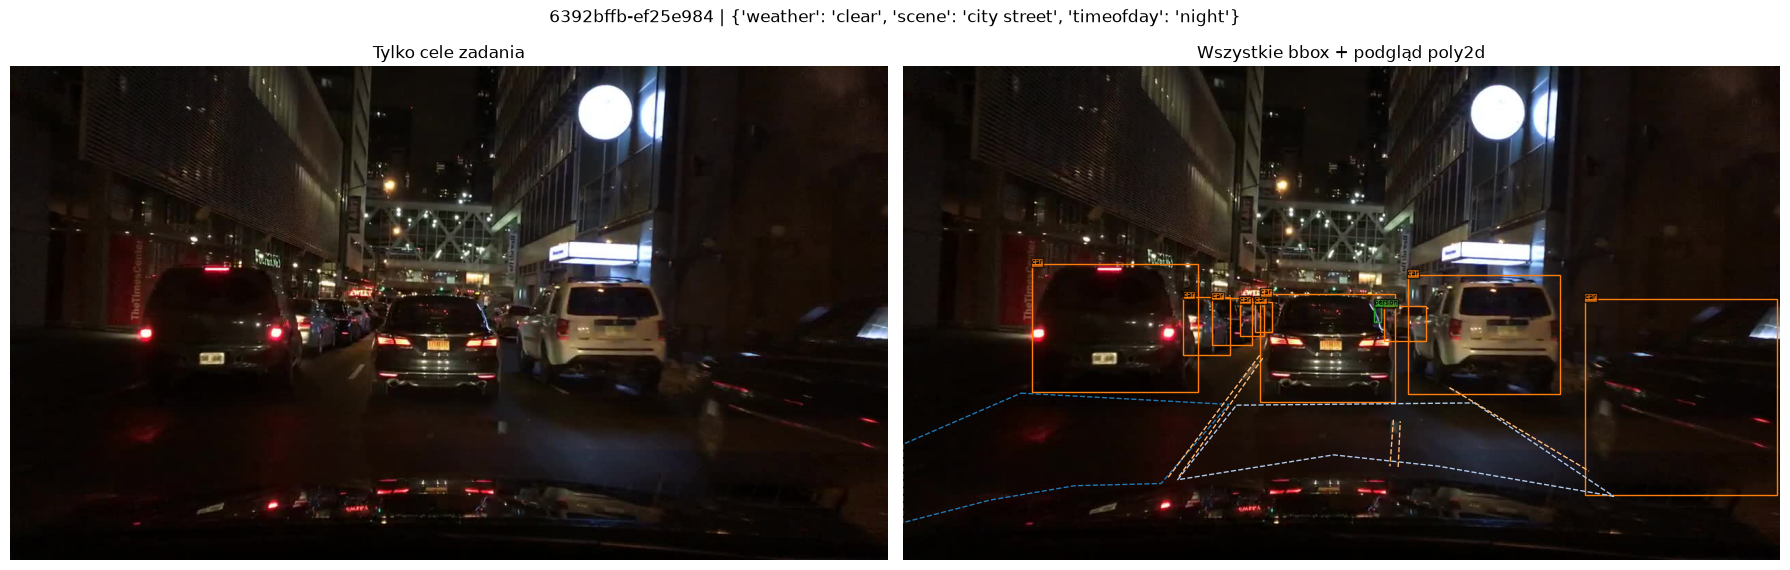

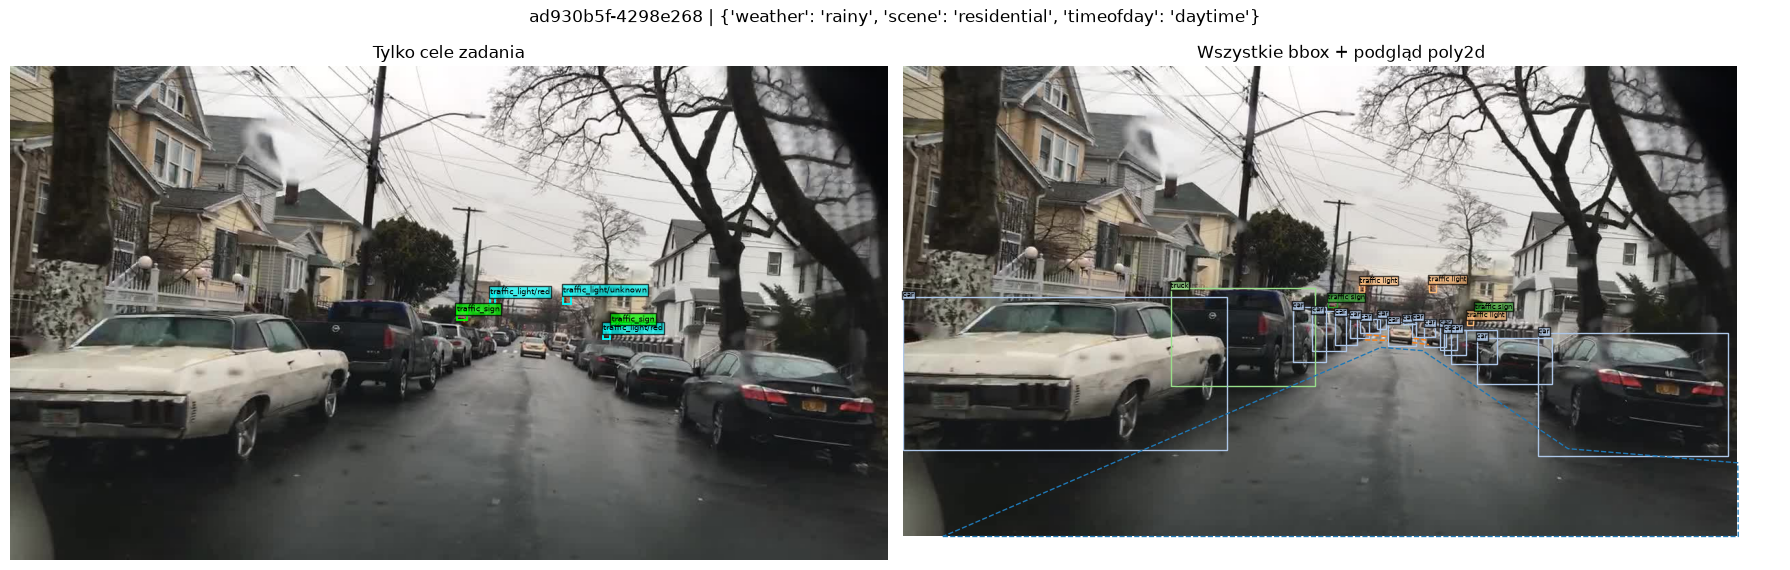

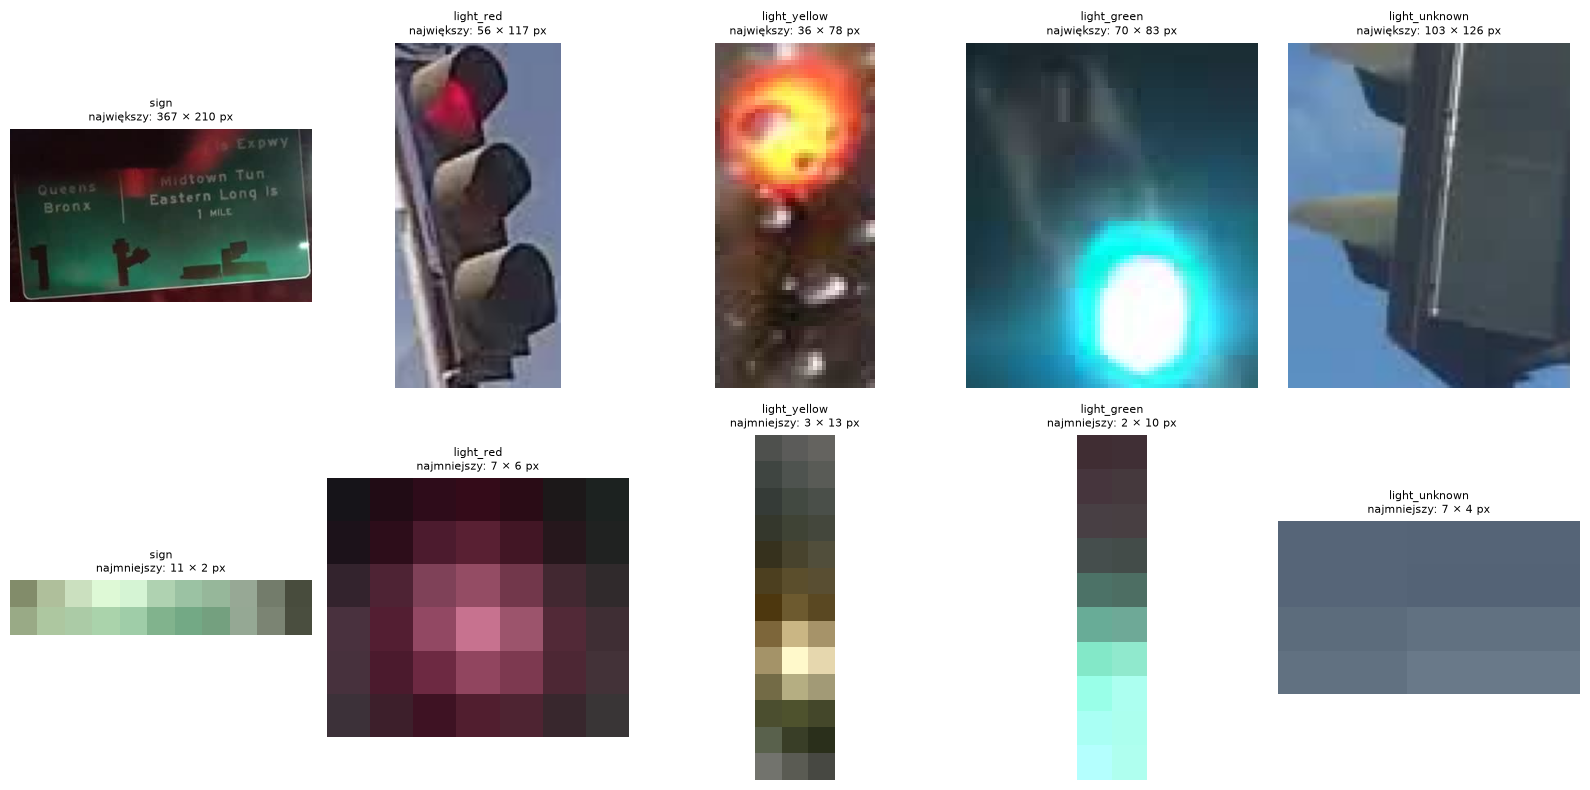

In [5]:
lookup = {r['id']:r for r in train}
negative = scene.loc[(scene.targets==0)&(scene.all_annotations>0),'id']
poly = scene.loc[scene.poly2d>0,'id']
for name in list(dict.fromkeys([*negative.head(1),*poly.head(1)])):
    record = lookup[name]
    im = load_image(ROOT/record['image'])
    truth,attrs,_ = annotations(ROOT/record['label'],im.shape)
    data = read_json(ROOT/record['label'])
    fig,axes = plt.subplots(1,2,figsize=(18,6))
    draw(im,truth,'Tylko cele zadania',axes[0])
    draw_all(im,data,axes[1]); axes[1].set_title('Wszystkie bbox + podgląd poly2d')
    fig.suptitle(name+' | '+str(attrs)); fig.tight_layout()
    fig.savefig(EDA/f'all_annotations_{name}.png',dpi=110); plt.show()
crop_gallery(ROOT,train,EDA)

## Rozmiary obiektów i rozkład atrybutów

obiekty
class         color           
traffic_light green       1133
              red          698
              unknown      983
              yellow        50
traffic_sign  NaN         3588

width                           height            \
                    mean       min         max       mean       min   
class                                                                 
traffic_light  15.658207  2.350666  102.881448  24.985715  4.316165   
traffic_sign   31.721054  4.393217  429.796111  26.002245  2.495508   

                           occluded              truncated               
                      max      mean    min   max      mean    min   max  
class                                                                    
traffic_light  139.486397  0.038059  False  True  0.033170  False  True  
traffic_sign   252.986416  0.113991  False  True  0.027592  False  True

,udział <10 px
class,
traffic_light,0.302025
traffic_sign,0.162207


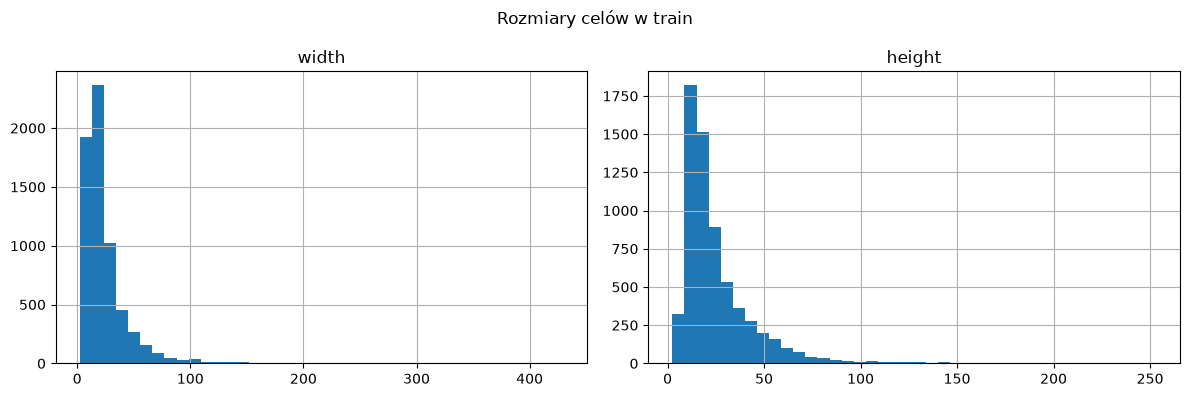

,liczba obrazów
weather,
clear,546
undefined,128
overcast,127
snowy,88
rainy,83
partly cloudy,78


,liczba obrazów
timeofday,
daytime,570
night,413
dawn/dusk,65
undefined,2


,liczba obrazów
scene,
city street,650
highway,253
residential,130
undefined,8
parking lot,8
tunnel,1


In [6]:
if not obj.empty:
    display(obj.groupby(['class','color'],dropna=False).size().rename('obiekty').to_frame())
    display(obj.groupby('class')[['width','height','occluded','truncated']].agg(['mean','min','max']))
    display(obj.assign(tiny=(obj.width<10)|(obj.height<10)).groupby('class').tiny.mean().rename('udział <10 px').to_frame())
    obj[['width','height']].hist(bins=40,figsize=(12,4))
    plt.suptitle('Rozmiary celów w train'); plt.tight_layout(); plt.show()
for column in ('weather','timeofday','scene'):
    if column in scene:
        display(scene[column].value_counts(dropna=False).rename('liczba obrazów').to_frame())

## Podsumowanie podejść klasycznych

| Podejście | Zasada działania | Zalety | Ograniczenia |
|---|---|---|---|
| HSV + morfologia + geometria | maski kolorów, kontury, filtry kształtu | szybki i przejrzysty baseline (notebook 02) | wrażliwość na oświetlenie i tło |
| Propozycje + cechy ręczne + RF | HOG, HSV, geometria, krawędzie + las losowy | nieliniowe łączenie cech (notebook 03) | ograniczony przez recall propozycji |